# 6. Evaluating results and screening descriptors

## tl;dr

The paper summary contains 43,889 predictions per reported phase. The
median phase F1 is 0.758; H, G and E have the lowest F1 values (0.586,
0.672 and 0.683) and fewer than 400 positive examples each.

## Context & Methods

This notebook checks saved result tables, recomputes selected metrics,
combines phase and temperature outputs, and ranks descriptors with a
Mann–Whitney U test. Saved paper artefacts are read-only inputs.

### Key Assumptions

The paper CSV files are fixed outputs from the reported workflow. The
five-row descriptor example is used only to demonstrate the statistical
API; its p-values are not scientific evidence.

### 1. Read the fixed paper summary

**Caution.** Treat published summary tables as read-only reference inputs and write any recalculated tables to `results/`.

**Extension.** Add confidence intervals or bootstrap distributions when reporting differences between model families.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
EXAMPLE_DATA = PROJECT_ROOT / "examples" / "data"
RESULT_DIRECTORY = PROJECT_ROOT / "results"
RESULT_DIRECTORY.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PAPER_RESULTS = PROJECT_ROOT / "paper" / "results"
summary = pd.read_csv(PAPER_RESULTS / "paper_summary.csv")
display(summary)

,type,npos,N,acc,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
0,N,20662,43889,0.92408,0.92029,0.91860,0.91944,7.388669,11.440307,11.048438,12.523904
1,A,9531,43889,0.93568,0.84713,0.85530,0.85119,8.395594,12.281560,10.111967,12.273427
2,B,1710,43889,0.97938,0.68538,0.76153,0.72145,10.722627,12.779174,13.325514,15.315523
3,C,6444,43889,0.96108,0.86887,0.86645,0.86766,7.995681,11.007055,8.773100,10.651999
4,E,392,43889,0.99481,0.62755,0.75000,0.68333,10.109548,12.959335,14.087394,15.012554
5,F,307,43889,0.99683,0.71987,0.80657,0.76076,6.200850,8.644574,9.111894,11.469691
6,G,328,43889,0.99540,0.63110,0.71875,0.67208,8.542749,11.901828,10.090222,10.921457
7,H,52,43889,0.99907,0.55769,0.61702,0.58586,13.109982,18.969455,14.037840,13.850166
8,I,274,43889,0.99702,0.74818,0.76779,0.75786,6.134303,16.290632,10.118507,18.049800
9,J,67,43889,0.99909,0.68657,0.70769,0.69697,6.436363,6.874889,11.500400,15.221551


### 2. Visualise accuracy and F1

**Caution.** Accuracy is dominated by negative examples for rare phases and should not be interpreted without F1 and positive counts.

**Extension.** A precision–recall curve from molecule-level probabilities is more informative when selecting a decision threshold.

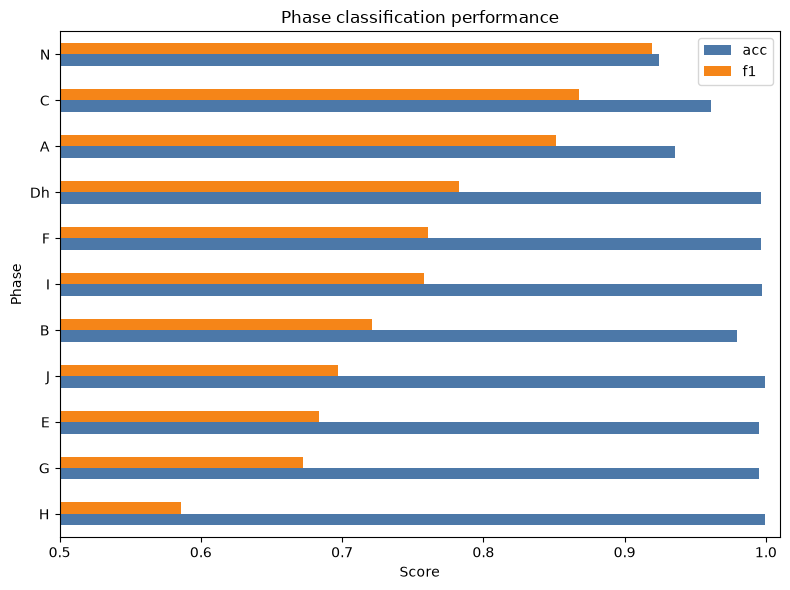

Median F1: 0.758


In [2]:
ordered = summary.sort_values("f1")
axis = ordered.plot.barh(
    x="type", y=["acc", "f1"], figsize=(8, 6), xlim=(0.5, 1.01),
    color=["#4C78A8", "#F58518"],
)
axis.set_title("Phase classification performance")
axis.set_xlabel("Score")
axis.set_ylabel("Phase")
plt.tight_layout()
plt.show()
print("Median F1:", round(summary["f1"].median(), 3))

### 3. Recompute selected molecule-level summaries

**Caution.** The detailed CSV is larger than the summary; restrict columns where memory is limited and verify the row count.

**Extension.** The same summary function accepts any set of `true_`, `pred_` and optional confidence columns from a new model.

In [3]:
from lc_qspr.evaluation import (
    classification_details, classification_summary, temperature_summary,
)

detailed = pd.read_csv(PAPER_RESULTS / "paper_GATv2Conv.csv", low_memory=False)
selected_phase_targets = ["Ntype", "Atype", "Btype"]
recomputed_phase = classification_summary(detailed, selected_phase_targets)
recomputed_temperature = temperature_summary(detailed, ["Clearing", "Melting"])
display(recomputed_phase)
display(recomputed_temperature)
classification_report, confusion_matrix = classification_details(
    detailed, "Ntype"
)
display(classification_report)
display(confusion_matrix)
assert len(detailed) == int(summary["N"].iloc[0])

,npos,N,classes,multiclass_accuracy,cohen_kappa,matthews_correlation,accuracy,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
type,,,,,,,,,,,,,,
N,20662,43889,3,0.920823,0.854642,0.854648,0.924081,0.920288,0.918599,0.919443,7.388669,11.440307,11.048438,12.523904
A,9531,43889,2,0.935679,0.810167,0.810182,0.935679,0.847130,0.855297,0.851194,8.395594,12.281560,10.111967,12.273427
B,1710,43889,2,0.979380,0.710777,0.711841,0.979380,0.685380,0.761533,0.721453,10.722627,12.779174,13.325514,15.315523


,n,mae,standard_deviation,median_absolute_error
target,,,,
Clearing,43886,10.621435,15.263108,5.376530
Melting,43887,12.832170,14.895446,8.402229


,precision,recall,f1-score,support
0,0.928975,0.927455,0.928214,23227.000000
1,0.919033,0.923783,0.921402,18185.000000
2,0.856258,0.836899,0.846468,2477.000000
accuracy,0.920823,0.920823,0.920823,0.920823
macro avg,0.901422,0.896046,0.898695,43889.000000
weighted avg,0.920751,0.920823,0.920778,43889.000000


predicted,0,1,2
true,,,
0,21542,1403,282
1,1320,16799,66
2,327,77,2073


### 4. Combine phase and temperature result tables

**Caution.** Joining by positional row number is unsafe after filtering; preserve and align a stable `ID` index.

**Extension.** This utility supports hybrid models, for example LightGBM phases with GNN temperatures.

In [4]:
from lc_qspr.evaluation import combine_phase_and_temperature_results

indexed = detailed.set_index("ID")
phase_columns = ["SMILES", "Phases"] + [
    column for column in indexed if column.startswith(("true_Ntype", "pred_Ntype"))
]
temperature_columns = ["SMILES", "Phases"] + [
    column for column in indexed
    if column.startswith(("true_Melting", "pred_Melting", "error_Melting"))
]
combined = combine_phase_and_temperature_results(
    indexed[phase_columns], indexed[temperature_columns]
)
assert combined.index.equals(indexed.index)
assert combined.columns.tolist().count("SMILES") == 1
print("Combined table shape:", combined.shape)
print("Combined columns:", list(combined.columns))

Combined table shape: (43889, 7)
Combined columns: ['SMILES', 'Phases', 'true_Ntype', 'pred_Ntype', 'true_Melting', 'pred_Melting', 'error_Melting']


### 5. Rank descriptors with the Mann–Whitney U test

**Caution.** The five-row example has virtually no statistical power and is used only to verify the calculation path.

**Extension.** For a paper analysis, correct for multiple testing, report effect sizes and validate top descriptors on held-out chemistry.

In [5]:
from lc_qspr.descriptors import select_descriptor_names
from lc_qspr.preprocessing import read_table
from lc_qspr.statistics import mann_whitney_descriptors

descriptor_table = read_table(EXAMPLE_DATA / "sample_desc.csv")
candidate_descriptors = select_descriptor_names(descriptor_table, "All")[:30]
screening = mann_whitney_descriptors(
    descriptor_table, "Ntype", candidate_descriptors
)
display(screening.head(10))

,descriptor,u_statistic,p_value,positive_n,negative_n,positive_median,negative_median,benjamini_hochberg_q
0,nO,5.0,0.332922,2,3,3.500000,1.000000,1.0
1,nHetero,5.0,0.332922,2,3,3.500000,1.000000,1.0
2,ABCGG,5.0,0.400000,2,3,13.887308,12.052430,1.0
3,VR3_A,5.0,0.400000,2,3,8.029369,6.504674,1.0
4,VE2_A,1.0,0.400000,2,3,0.153719,0.176434,1.0
5,nHeavyAtom,4.5,0.553617,2,3,25.500000,22.000000,1.0
6,ABC,4.0,0.800000,2,3,18.781094,16.223016,1.0
7,nC,4.0,0.800000,2,3,22.000000,21.000000,1.0
8,nH,4.0,0.800000,2,3,30.000000,28.000000,1.0
9,nAtom,4.0,0.800000,2,3,55.500000,50.000000,1.0


### 6. Plot the leading descriptor distributions

**Caution.** Boxplots from tiny or highly imbalanced groups can look persuasive despite unstable estimates; always show sample counts.

**Extension.** Overlay individual points or use scaffold-stratified panels to reveal whether a descriptor signal is driven by a narrow chemical family.

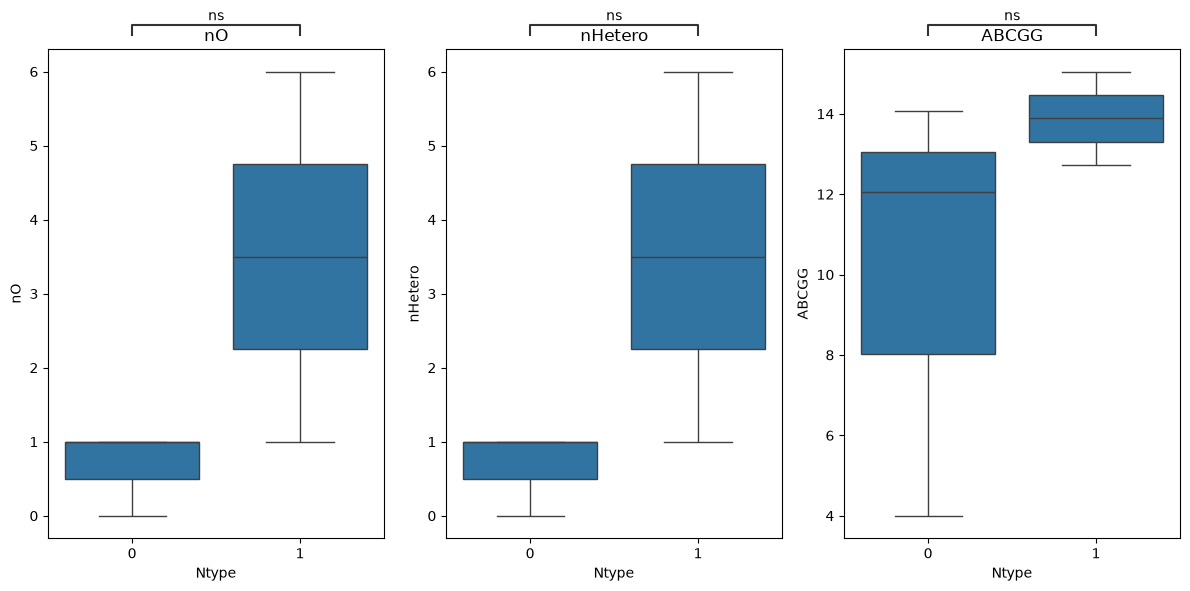

In [6]:
from lc_qspr.statistics import plot_descriptor_boxplots

leading_descriptors = screening["descriptor"].head(3).tolist()
plot_descriptor_boxplots(
    descriptor_table, "Ntype", leading_descriptors,
    maximum_descriptors=3,
)
plt.show()